# FidelProbe

Do small VLMs understand the consonant × vowel structure of the Ethiopic script? Qwen3-VL-2B-Instruct on 2,592 probes, with Korean Hangul as a control.

## Setup

In [1]:
!pip -q install -U "transformers>=4.57" accelerate "huggingface_hub>=1.6"
!apt-get -qq install -y fonts-noto-core fonts-noto-cjk fonts-sil-abyssinica > /dev/null
!git clone -q https://github.com/aleale2121/fatima_challenge.git
%cd fatima_challenge/fidelprobe
import os
from google.colab import userdata
os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')

fatal: destination path 'fatima_challenge' already exists and is not an empty directory.
/content/fatima_challenge/fidelprobe


## Build the probe set

In [2]:
!python build_dataset.py --out ../data --seed 0

Counter({('minimal_pair', 'eth'): 288, ('minimal_pair', 'hangul'): 246, ('decompose_consonant', 'eth'): 231, ('identify_order', 'eth'): 231, ('compose', 'eth'): 231, ('transform', 'eth'): 231, ('ocr_char', 'eth'): 231, ('decompose_consonant', 'hangul'): 133, ('identify_order', 'hangul'): 133, ('compose', 'hangul'): 133, ('transform', 'hangul'): 133, ('ocr_char', 'hangul'): 133, ('ocr_word', 'eth'): 96, ('ocr_word', 'hangul'): 82, ('ocr_line', 'eth'): 30, ('ocr_line', 'hangul'): 30})


## Run the model

In [3]:
MODEL = "Qwen/Qwen3-VL-2B-Instruct"
!python run_eval.py --model $MODEL --data ../data --out ../results

2592 items, 2592 to run
config.json: 100% 1.50k/1.50k [00:00<00:00, 2.65MB/s]

model.safetensors: downloading bytes:   2% 93.3M/4.26G [00:00<00:24, 167MB/s, 5.83MB/s  ]
model.safetensors: downloading bytes:  13% 534M/4.26G [00:02<00:12, 296MB/s, 44.2MB/s  ]
model.safetensors: downloading bytes:  14% 608M/4.26G [00:02<00:11, 324MB/s, 49.5MB/s  ]
model.safetensors: downloading bytes:  76% 3.25G/4.26G [00:05<00:01, 606MB/s,  249MB/s  ]
model.safetensors: downloading bytes:  87% 3.69G/4.26G [00:07<00:02, 202MB/s,  247MB/s  ]
model.safetensors: reconstructing file:  80% 3.42G/4.26G [00:10<00:02, 372MB/s,  152MB/s  ]
model.safetensors: downloading bytes: 100% 3.70G/3.70G [00:13<00:00, 276MB/s,  234MB/s  ]
model.safetensors: reconstructing file: 100% 4.26G/4.26G [00:13<00:00, 318MB/s,  247MB/s  ]
Loading weights: 100% 625/625 [00:01<00:00, 591.02it/s]
generation_config.json: 100% 269/269 [00:00<00:00, 1.40MB/s]
preprocessor_config.json: 100% 390/390 [00:00<00:00, 1.58MB/s]
chat_template.json:

## Tokenizer check and scoring

### Results: `Qwen/Qwen3-VL-2B-Instruct`

**Headline: Ethiopic vs the matched Hangul control (accuracy)**

| Task | Ethiopic | Hangul | What it tests |
|---|---|---|---|
| ocr_char | 0.0% | 63.9% | read one rendered character |
| decompose_consonant | 10.4% | 40.6% | name the base consonant of a character |
| identify_order | 20.8% | 48.9% | name the vowel order 1-7 (chance 14%) |
| compose | 3.0% | 0.0% | consonant + order -> character |
| transform | 1.3% | 0.0% | same consonant, new vowel order |
| minimal_pair | 94.8% | 98.8% | same/different spelling (chance 50%) |

**Minimal pairs: accuracy by the kind of difference**

| | identical | one vowel form changed | one consonant changed |
|---|---|---|---|
| Ethiopic (Amharic) | 100.0% | 86.5% | 97.9% |
| Hangul (Korean control) | 100.0% | 100.0% | 96.3% |

**Rendered-text OCR (character error rate, and what the errors are)**

| Set | CER | exact match | vowel-form subs | consonant subs | other-script subs | deletions | insertions |
|---|---|---|---|---|---|---|---|
| ocr_word / eth | 820.5% | 0.0% | 0 | 0 | 295 | 1 | 2147 |
| ocr_word / hangul | 4.9% | 92.7% | 1 | 3 | 2 | 0 | 2 |
| ocr_line / eth | 356.0% | 0.0% | 0 | 0 | 353 | 0 | 1223 |
| ocr_line / hangul | 1.7% | 80.0% | 1 | 3 | 0 | 0 | 1 |

**Ethiopic single-character errors by type**

| Task | vowel form (right consonant) | consonant | both | other script | n wrong |
|---|---|---|---|---|---|
| ocr_char | 0 | 0 | 0 | 231 | 231 |
| compose | 0 | 22 | 0 | 202 | 224 |
| transform | 80 | 32 | 13 | 103 | 228 |

**Ethiopic single-character OCR accuracy by vowel order**

| 1 (ä) | 2 (u) | 3 (i) | 4 (a) | 5 (e) | 6 (ə) | 7 (o) |
|---|---|---|---|---|---|---|
| 0.0% | 0.0% | 0.0% | 0.0% | 0.0% | 0.0% | 0.0% |

**Tokenizer view of the Fidel grid**

| | single-token chars | mean tokens / char | consonants whose 7 forms share a token |
|---|---|---|---|
| Ethiopic (Amharic) | 108/231 | 1.53 | 3/33 |
| Hangul (Korean control) | 133/133 | 1.00 | 0/19 |

Tokens per character on sentences: eth 1.28, hangul 0.75, english 0.25.



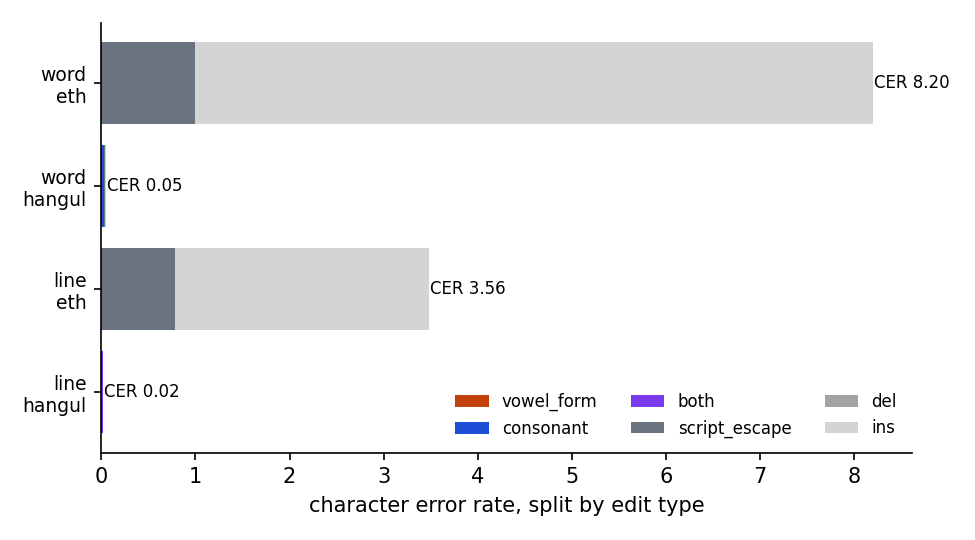

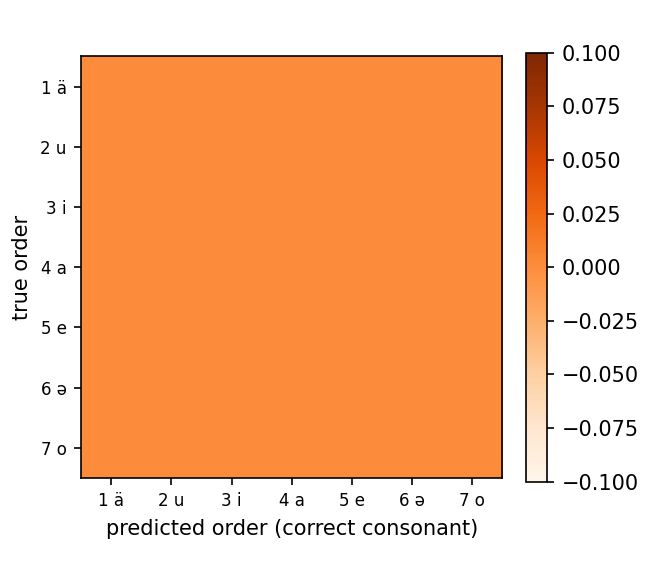

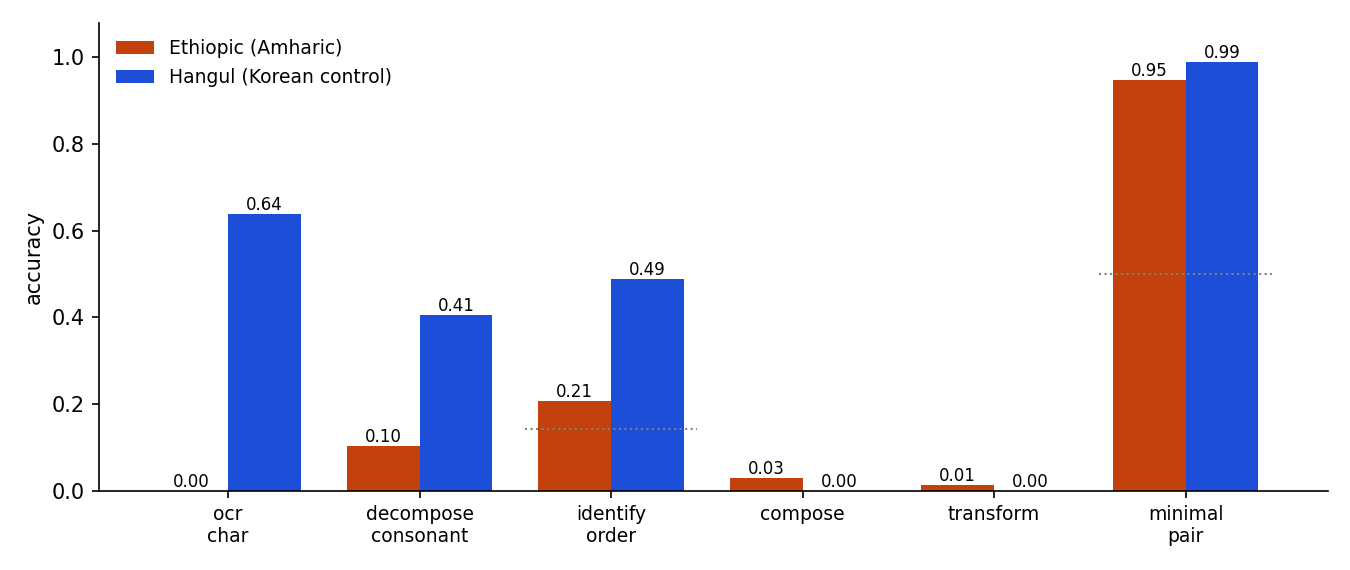

In [9]:
!python tokenizer_probe.py --model $MODEL --out ../results > /dev/null
!python analyze.py --data ../data --results ../results > /dev/null
from IPython.display import Image, Markdown, display
import glob
display(Markdown(open(glob.glob('../results/RESULTS_*.md')[0]).read().split('![')[0]))
for p in sorted(glob.glob('../results/fig_*.png')): display(Image(p))

## Some Ethiopic mistakes

In [10]:
import pandas as pd
df = pd.read_json(glob.glob('../results/scored_*.jsonl')[0], lines=True)
df[(df.script == 'eth') & (~df.correct)][['task', 'gold', 'answer', 'raw']].sample(20, random_state=0)

,task,gold,answer,raw
2039,ocr_char,ሸ,丶,丶
7,transform,ሄ,e,e
842,compose,ፃ,a,a
2465,ocr_line,እህቴ ዘፈን ትዘፍናለች።,აუტ მარ ტინერალი:,აუტ მარ ტინერალი:
629,identify_order,4,7,7
49,identify_order,6,1,1
869,identify_order,1,6,6
228,decompose_consonant,ቀ,ቁ,ቁ
546,compose,ዕ,ə,ə
278,compose,በ,ä,ä
